# Step 7 – Federated Learning with FedAvg
**Project:** Paper Leak Sentiment Analysis Using Federated Learning – **Objective 2**

> *Train a sentiment model on comments from 5 platforms **without any platform sharing its comments**.*

### How FedAvg works
```
repeat for R rounds:
    1. Server  → sends the current global model (W, b) to all 5 clients
    2. Client k → trains it on its OWN comments for E epochs        (data never leaves the client)
    3. Client k → sends back only the updated weights (W_k, b_k)
    4. Server  → averages them, weighted by data size:   W = Σ (n_k / n) · W_k
```

| Setting | Value |
|---|---|
| Clients | 5 platforms: YouTube, X, Instagram, Reddit, NewsPortal (non-IID, Step 6) |
| Model | Softmax (multinomial logistic) regression, written from scratch in NumPy |
| Features | Hashing vectorizer, 262,144 features, computed **independently on each client** |
| Rounds × local epochs | 40 × 2 |
| Local optimiser | mini-batch SGD, batch 64, learning rate 1.2 decaying each round |

The code is in `src/federated.py`. FedAvg is implemented directly rather than through a framework (such as Flower), so every step of the algorithm is visible.

In [1]:
import sys, json
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
from matplotlib import font_manager
FONT = "Segoe UI" if any(f.name == "Segoe UI" for f in font_manager.fontManager.ttflist) else "DejaVu Sans"
SURFACE, INK, INK2, MUTED, GRID, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
PLATFORMS = ["YouTube", "X", "Instagram", "Reddit", "NewsPortal"]
CAT = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]; PCOL = dict(zip(PLATFORMS, CAT))
plt.rcParams.update({"font.family": FONT, "font.size": 10, "figure.facecolor": SURFACE, "axes.facecolor": SURFACE,
    "savefig.facecolor": SURFACE, "axes.edgecolor": AXIS, "axes.labelcolor": INK2, "xtick.color": MUTED, "ytick.color": MUTED,
    "xtick.labelcolor": INK2, "ytick.labelcolor": INK2, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True, "legend.frameon": False,
    "savefig.dpi": 200, "savefig.bbox": "tight"})
FIG, TAB = ROOT / "results/figures", ROOT / "results/tables"
def title(ax, main, sub=None):
    ax.set_title(main, loc="left", fontsize=13, fontweight="bold", color=INK, pad=24 if sub else 10)
    if sub: ax.text(0, 1.02, sub, transform=ax.transAxes, fontsize=9.5, color=INK2, va="bottom")

## 1. System architecture

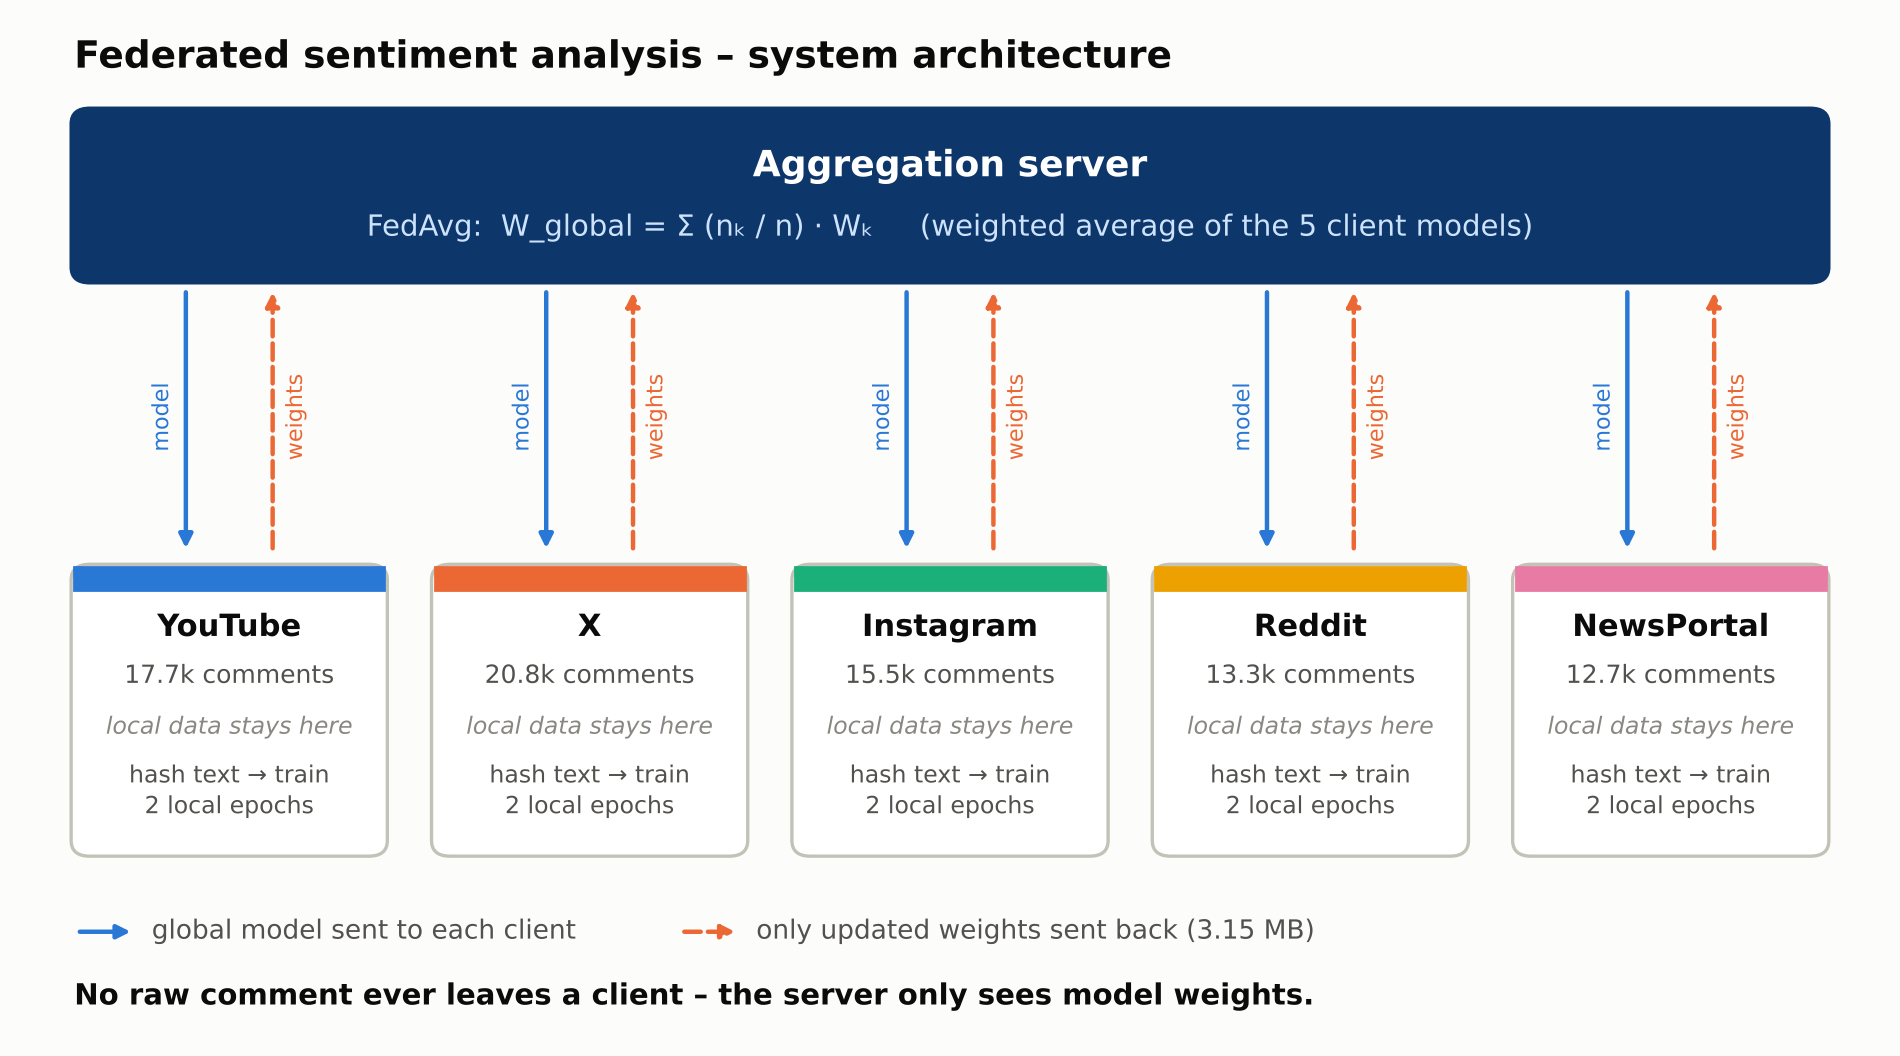

In [2]:
from matplotlib.patches import FancyBboxPatch
fig, ax = plt.subplots(figsize=(12, 6.6)); ax.set_xlim(0, 12); ax.set_ylim(-1.05, 6.75); ax.axis("off")
def box(x, y, w, h, fc, ec, lw=1.2):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.02,rounding_size=0.12", fc=fc, ec=ec, lw=lw))
# server (spans all clients)
box(0.35, 4.75, 11.3, 1.3, "#0d366b", "#0d366b")
ax.text(6.0, 5.62, "Aggregation server", ha="center", va="center", color="white", fontsize=13, fontweight="bold")
ax.text(6.0, 5.15, "FedAvg:  W_global = Σ (nₖ / n) · Wₖ     (weighted average of the 5 client models)",
        ha="center", va="center", color="#cde2fb", fontsize=10.5)
# clients
xs = np.linspace(0.35, 9.65, 5); w = 2.0
sizes = {"YouTube": "17.7k", "X": "20.8k", "Instagram": "15.5k", "Reddit": "13.3k", "NewsPortal": "12.7k"}
for x, p in zip(xs, PLATFORMS):
    box(x, 0.35, w, 2.2, "#ffffff", AXIS)
    ax.add_patch(FancyBboxPatch((x, 2.37), w, 0.18, boxstyle="square,pad=0", fc=PCOL[p], ec=PCOL[p]))
    ax.text(x + w / 2, 2.02, p, ha="center", fontsize=11, fontweight="bold", color=INK)
    ax.text(x + w / 2, 1.66, f"{sizes[p]} comments", ha="center", fontsize=9, color=INK2)
    ax.text(x + w / 2, 1.27, "local data stays here", ha="center", fontsize=8.5, color=MUTED, style="italic")
    ax.text(x + w / 2, 0.66, "hash text → train\n2 local epochs", ha="center", fontsize=8.5, color=INK2, linespacing=1.4)
    cx = x + w / 2
    ax.annotate("", xy=(cx - 0.28, 2.65), xytext=(cx - 0.28, 4.7), arrowprops=dict(arrowstyle="-|>", color="#2a78d6", lw=1.6))
    ax.annotate("", xy=(cx + 0.28, 4.7), xytext=(cx + 0.28, 2.65), arrowprops=dict(arrowstyle="-|>", color="#eb6834", lw=1.6, ls="--"))
    ax.text(cx - 0.36, 3.7, "model", rotation=90, ha="right", va="center", fontsize=8, color="#2a78d6")
    ax.text(cx + 0.36, 3.7, "weights", rotation=90, ha="left", va="center", fontsize=8, color="#eb6834")
# legend + message under the clients
ax.annotate("", xy=(0.75, -0.25), xytext=(0.35, -0.25), arrowprops=dict(arrowstyle="-|>", color="#2a78d6", lw=1.6))
ax.text(0.85, -0.25, "global model sent to each client", va="center", fontsize=9.5, color=INK2)
ax.annotate("", xy=(4.65, -0.25), xytext=(4.25, -0.25), arrowprops=dict(arrowstyle="-|>", color="#eb6834", lw=1.6, ls="--"))
ax.text(4.75, -0.25, "only updated weights sent back (3.15 MB)", va="center", fontsize=9.5, color=INK2)
ax.text(0.35, -0.75, "No raw comment ever leaves a client – the server only sees model weights.", ha="left", va="center", fontsize=10.5, fontweight="bold", color=INK)
ax.text(0.35, 6.6, "Federated sentiment analysis – system architecture", fontsize=13.5, fontweight="bold", color=INK, va="top")
fig.savefig(FIG / "F1_fl_architecture.png"); plt.show()

## 2. Run federated training

In [3]:
import federated
federated.main()      # ~1.5 minutes: 40 FedAvg rounds + the centralized reference with the same model

Loading the 5 platform clients (each one hashes its own text)...


  YouTube     17,652 comments
  X           20,846 comments
  Instagram   15,465 comments
  Reddit      13,347 comments
  NewsPortal  12,692 comments

FedAvg: 40 rounds, 2 local epoch(s), lr 1.2


round   1  test acc 0.8596  macro-F1 0.8591  (1.01s)


round   5  test acc 0.9050  macro-F1 0.9047  (0.89s)


round  10  test acc 0.9131  macro-F1 0.9128  (0.89s)


round  15  test acc 0.9166  macro-F1 0.9163  (1.2s)


... (2 outputs left out)

round  30  test acc 0.9194  macro-F1 0.9191  (0.88s)


round  35  test acc 0.9191  macro-F1 0.9188  (0.84s)


round  40  test acc 0.9190  macro-F1 0.9187  (1.43s)

Centralized reference (same model, pooled data)...



FedAvg      : accuracy 0.9190  macro-F1 0.9187
Centralized : accuracy 0.9225  macro-F1 0.9222
Gap         : 0.35 percentage points   |   raw comments shared: 0


In [4]:
hist   = pd.read_csv(TAB / "fedavg_history.csv")
hist_c = pd.read_csv(TAB / "centralized_softmax_history.csv")
summary = json.loads((ROOT / "reports/fedavg_summary.json").read_text())
cent = pd.read_csv(TAB / "centralized_results.csv")

## 3. Convergence: does the federated model catch up with centralized training?

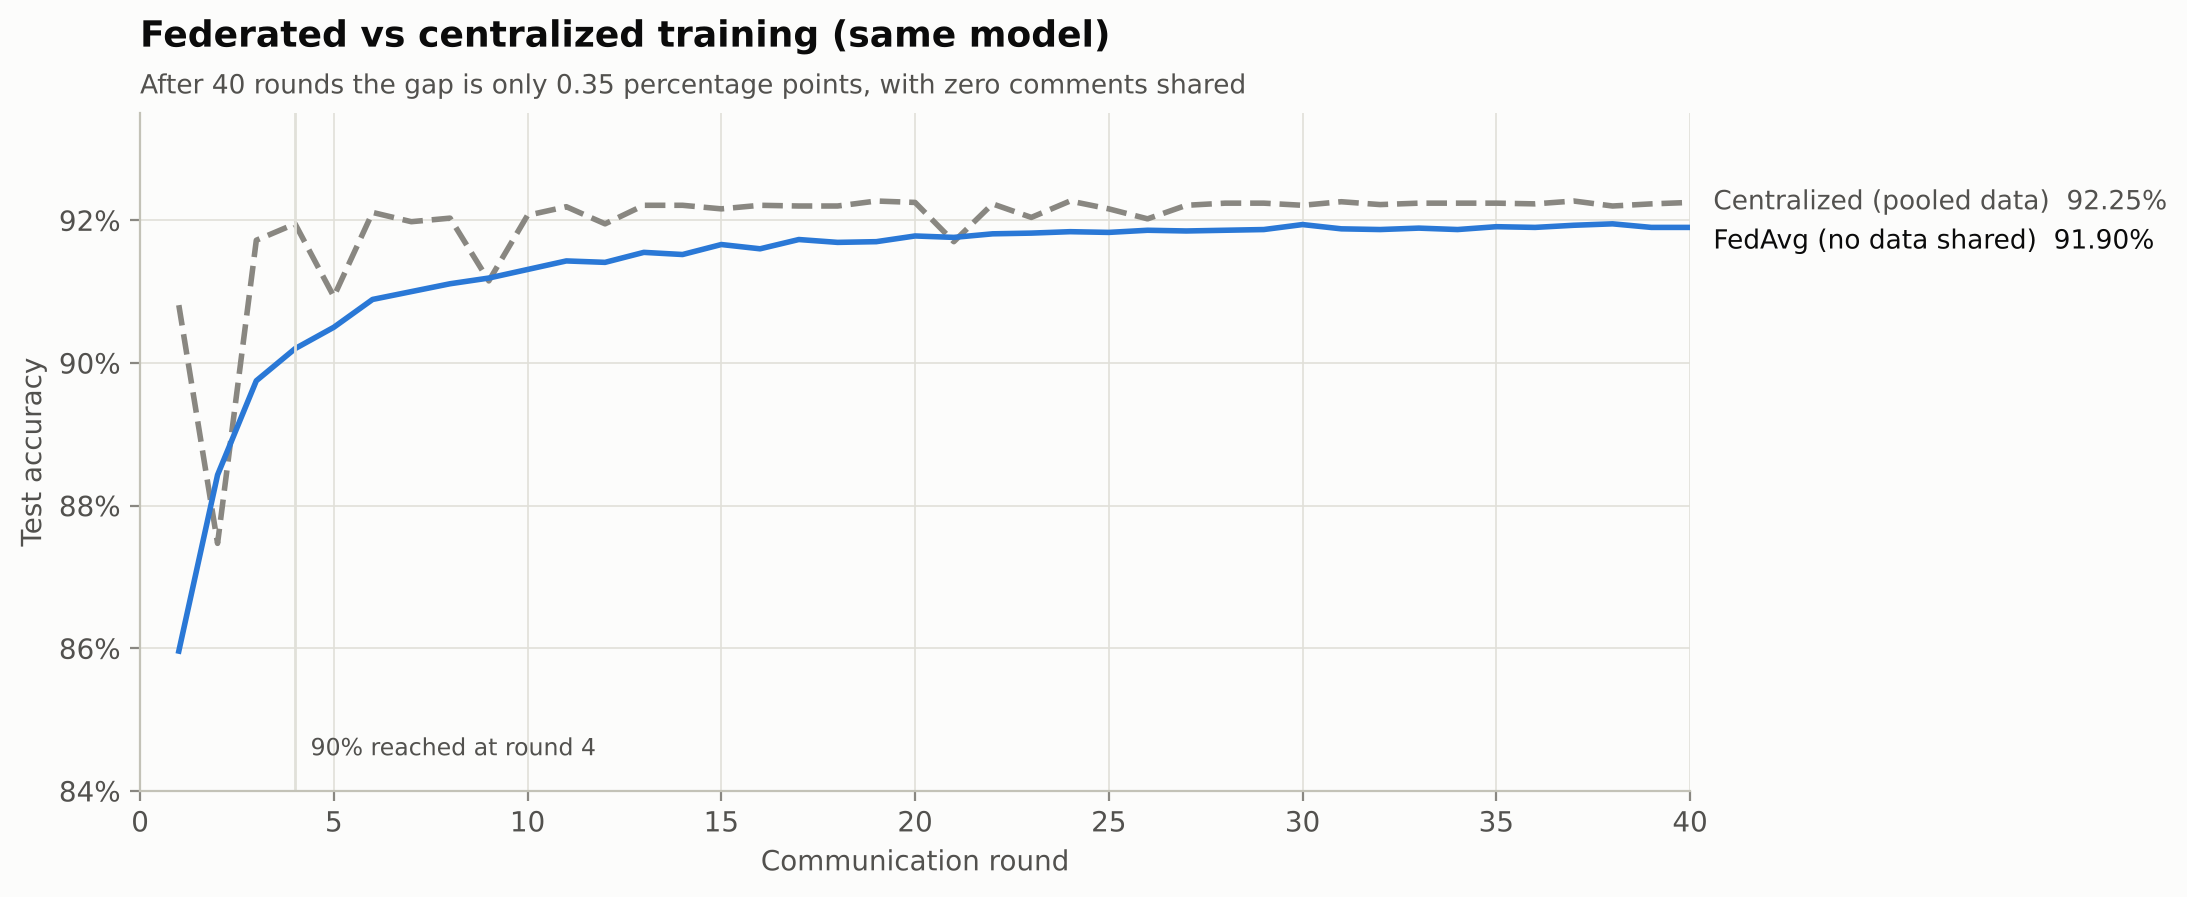

In [5]:
fig, ax = plt.subplots(figsize=(10, 4.4))
ax.plot(hist_c["round"], hist_c.test_accuracy, color=MUTED, lw=2, ls="--")
ax.plot(hist["round"], hist.test_accuracy, color=CAT[0], lw=2)
fa, ca = hist.test_accuracy.iloc[-1], hist_c.test_accuracy.iloc[-1]
ax.text(40.6, ca, f"Centralized (pooled data)  {ca:.2%}", va="center", fontsize=9.5, color=INK2)
ax.text(40.6, fa - 0.002, f"FedAvg (no data shared)  {fa:.2%}", va="center", fontsize=9.5, color=INK)
ax.set_xlim(0, 40); ax.set_ylim(0.84, 0.935); ax.set_xlabel("Communication round")
ax.yaxis.set_major_formatter(lambda x, _: f"{x:.0%}"); ax.set_ylabel("Test accuracy")
r90 = int(hist[hist.test_accuracy >= 0.90]["round"].min())
ax.axvline(r90, color=GRID, lw=1); ax.text(r90 + 0.4, 0.845, f"90% reached at round {r90}", fontsize=8.5, color=INK2)
title(ax, "Federated vs centralized training (same model)",
      f"After 40 rounds the gap is only {summary['gap_percentage_points']} percentage points, with zero comments shared")
fig.savefig(FIG / "F2_fedavg_convergence.png"); plt.show()

- The federated model improves quickly: it passes **90% accuracy within the first few rounds** and then levels off.
- It finishes **about 0.35 percentage points** below training the same model on pooled data.
- That small gap is the **price of privacy**: the clients never shared a single comment.

## 4. Does one global model work for every platform?

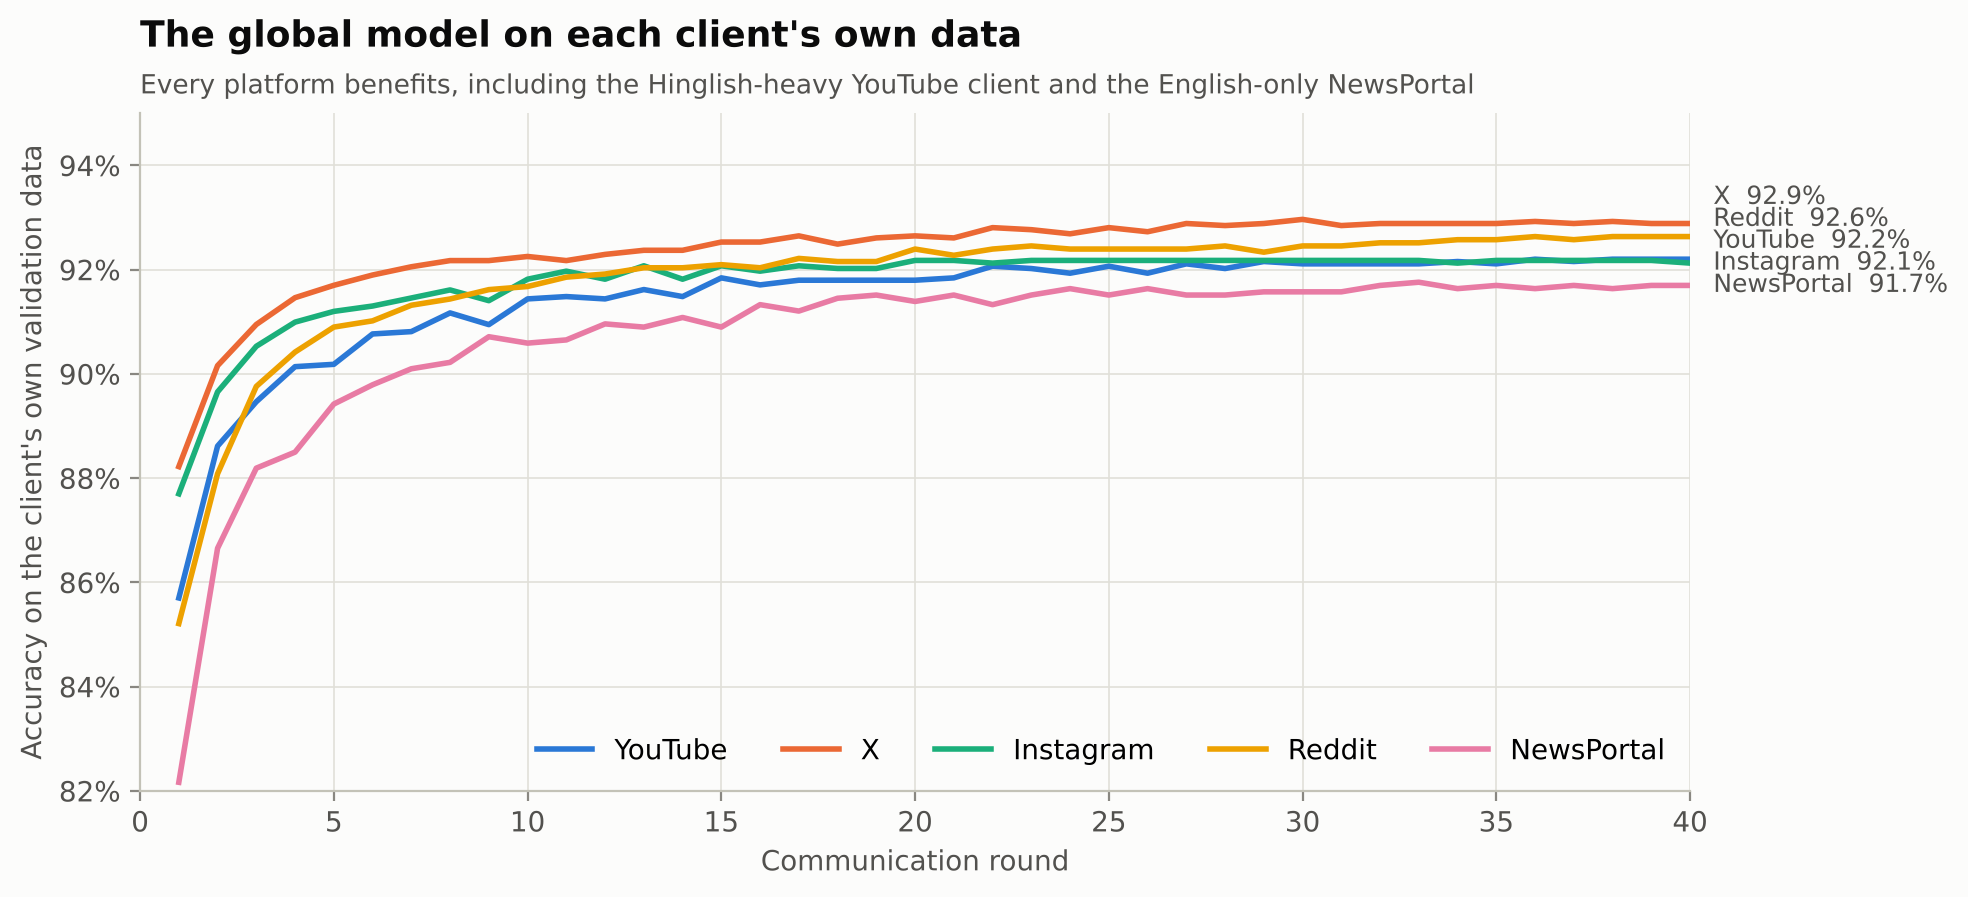

In [6]:
fig, ax = plt.subplots(figsize=(10, 4.4))
ends = []
for p in PLATFORMS:
    ax.plot(hist["round"], hist[f"val_acc_{p}"], color=PCOL[p], lw=2, label=p)
    ends.append((hist[f"val_acc_{p}"].iloc[-1], p))
ends.sort()
ypos = []
for v, p in ends:                       # spread the end labels so they don't overlap
    y = v if not ypos else max(v, ypos[-1] + 0.0042)
    ypos.append(y); ax.text(40.6, y, f"{p}  {v:.1%}", va="center", fontsize=9, color=INK2)
ax.set_xlim(0, 40); ax.set_ylim(0.82, 0.95); ax.set_xlabel("Communication round")
ax.yaxis.set_major_formatter(lambda x, _: f"{x:.0%}"); ax.set_ylabel("Accuracy on the client's own validation data")
ax.legend(ncol=5, loc="lower right")
title(ax, "The global model on each client's own data", "Every platform benefits, including the Hinglish-heavy YouTube client and the English-only NewsPortal")
fig.savefig(FIG / "F3_per_client_accuracy.png"); plt.show()

## 5. What does the server actually see?
The server only receives **numbers**: the weight matrix. Below are a few rows of one round's averaged weights. No sentence, word or user can be read from them directly.

In [7]:
m = np.load(ROOT / "models/fedavg_global_model.npz", allow_pickle=True)
W = m["W"]
rows = np.argsort(-np.abs(W).sum(1))[:6]
pd.DataFrame(W[rows], index=[f"feature #{r}" for r in rows], columns=[str(l) for l in m["labels"]]).round(3)

,negative,neutral,positive
feature #90988,5.314,-1.858,-3.455
feature #15687,-0.765,5.210,-4.445
feature #5247,-3.361,-0.856,4.217
feature #189081,4.195,-1.630,-2.565
feature #166365,4.032,-1.633,-2.399
feature #30384,-2.044,3.437,-1.393


In [8]:
comm = pd.DataFrame({"item": ["Model size (W + b, float32)", "Uploaded per round (5 clients)", "Total uploaded in 40 rounds", "Raw comments shared"],
                     "value": [f"{summary['model_size_mb']} MB", f"{summary['model_size_mb'] * 5:.2f} MB", f"{summary['total_uploaded_mb']:.0f} MB", "0"]})
comm.style.hide(axis="index")

item,value
"Model size (W + b, float32)",3.15 MB
Uploaded per round (5 clients),15.75 MB
Total uploaded in 40 rounds,629 MB
Raw comments shared,0


**Trade-off:** federated learning costs **communication**. Over 40 rounds the clients upload more megabytes of weights than the raw comments would take. In exchange, the comments themselves never leave their owners. The model could be made smaller (for example 65,536 hashing features ≈ 0.8 MB) if bandwidth mattered.

## 6. Try the federated model

In [9]:
from inference import predict_sentiment
examples = ["NEET paper leaked again, years of preparation wasted 😡",
            "Good decision to cancel the exam, a fair retest is better 👏",
            "When will the new exam date be announced?",
            "bhai phir se paper leak, kya fayda padhai ka",
            "police ne badhiya kaam kiya, gang pakda gaya",
            "retest ki date kab aayegi?",
            "पुलिस ने अच्छा काम किया",
            "Great job NTA, another leak 👏"]
pd.DataFrame([{k: r[k] for k in ("text", "label", "confidence")} for r in predict_sentiment(examples)])

,text,label,confidence
0,"NEET paper leaked again, years of preparation ...",negative,0.980
1,"Good decision to cancel the exam, a fair retes...",positive,0.972
2,When will the new exam date be announced?,neutral,0.837
3,"bhai phir se paper leak, kya fayda padhai ka",negative,0.815
4,"police ne badhiya kaam kiya, gang pakda gaya",positive,0.944
5,retest ki date kab aayegi?,neutral,0.944
6,पुलिस ने अच्छा काम किया,positive,0.786
7,"Great job NTA, another leak 👏",positive,0.503


The model handles English, Hinglish and Hindi. The last example is **sarcasm** (*"Great job … another leak 👏"*). Like most simple sentiment models, it reads the praise words and gets it wrong. This is a known limitation worth mentioning in the review.

## 7. Summary – Objective 2

In [10]:
best_c = cent.iloc[0]
pd.DataFrame({
  "Model": ["FedAvg (5 platform clients)", "Same model, centralized (pooled data)", f"Best centralized model ({best_c.model})"],
  "Privacy": ["✅ no comments shared", "❌ all comments pooled", "❌ all comments pooled"],
  "Test accuracy": [summary["fedavg_test_accuracy"], summary["centralized_test_accuracy"], best_c.accuracy],
  "Macro-F1": [summary["fedavg_test_macro_f1"], summary["centralized_test_macro_f1"], best_c.f1],
}).style.format({"Test accuracy": "{:.2%}", "Macro-F1": "{:.2%}"}).hide(axis="index")

Model,Privacy,Test accuracy,Macro-F1
FedAvg (5 platform clients),✅ no comments shared,91.90%,91.87%
"Same model, centralized (pooled data)",❌ all comments pooled,92.25%,92.22%
Best centralized model (Linear SVM),❌ all comments pooled,92.42%,92.39%


**Objective 2 achieved:** the federated model reaches **about 91.9% accuracy**, within about half a percentage point of centralized training, while every platform keeps its comments private.

**Next:** Step 8 – full comparison: centralized vs federated vs each platform training alone, non-IID vs IID clients, FedProx, and added privacy noise.